# 16 - Feature selection (experiment 08)

Experiments 05-07 added features without a real gain: all models sit at about 0.68 in CV. This notebook goes the
other way: **fewer features**. The learning curve of experiment 05 showed a large train / validation gap
(0.76 vs 0.68), so removing noisy or redundant features may reduce overfitting, and a smaller model is easier to
explain and possibly more robust on the private evaluation set.

Every selection is done **inside the CV folds**, as the first step of the pipeline: choosing features on the whole
train and then cross-validating would inflate the estimate.

| Section | Method |
|---|---|
| 1 | **Top-K by importance**: in each fold a quick LightGBM ranks the features on the training part only (`SelectFromModel`), the K best are kept. Accuracy vs K |
| 2 | **Redundancy**: features grouped by absolute Spearman correlation (|r| ≥ 0.95 / 0.9 / 0.8), one kept per group (`CorrelationFilter`, no target used) |
| 3 | **Whole groups**: v1 without `static` and / or `trend` (the groups that looked useless or redundant in experiment 02) |
| 4 | **PCA** (for completeness): it ignores the target and mixes all features, so it is not expected to help the trees |
| 5 | Stability of the selection across folds, and stress test of the best configuration |

Models: tuned LightGBM and LogReg of experiment 04. Comparisons are **paired** (same folds, seeds 42 / 7 / 123 × 5).

**Decision rule (fixed before running):** a configuration is adopted if it gains **≥ 0.3 points**, or if it loses
**≤ 0.1 points** with **at most 60%** of the features (simpler model at the same accuracy).

## 0. Setup

In [1]:
import os
import sys
import json
import time
import warnings
from collections import Counter
from pathlib import Path

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.models import get_model_specs, with_params
from src.selection import CorrelationFilter, selected_columns, top_k_selector, with_selection
from src.validation import REPEAT_SEEDS, SEED, cv_scores, stress_test

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 250)
PROC = ROOT / "data" / "processed"
OUT = PROC / "models"
OUT.mkdir(parents=True, exist_ok=True)

features = pd.read_pickle(PROC / "features_train.pkl")    # v1 features (notebook 03)
with open(PROC / "feature_groups.json") as f:
    groups = json.load(f)
y = features.pop("player_won")
CAT = groups["species_cat"]
NUM = [c for c in features.columns if c not in CAT]
X = features[NUM]
group_of = {c: g for g, cols in groups.items() if g not in ("robust", "species_cat") for c in cols}
print(f"battles: {len(X):,} | v1 features: {len(NUM)}")

specs = get_model_specs()
MODELS = {
    "lightgbm": with_params(specs["lightgbm"], {
        "model__colsample_bytree": 0.6286197472598067, "model__learning_rate": 0.006552992991573526,
        "model__min_child_samples": 106, "model__n_estimators": 1424, "model__num_leaves": 12,
        "model__reg_alpha": 0.6070874110546393, "model__reg_lambda": 2.7129089558470034,
        "model__subsample": 0.6629794526009424}),
    "logreg": with_params(specs["logreg"], {"model__C": 0.006690421166498805}),
}

battles: 10,000 | v1 features: 155


In [2]:
# Paired repeated CV: every configuration is scored on the same 15 folds as the baseline
score_cache = {}

def scores(key, model, cols=None):
    if key not in score_cache:
        Xc = X if cols is None else X[cols]
        score_cache[key] = np.concatenate([cv_scores(model, Xc, y, seed=s) for s in REPEAT_SEEDS])
    return score_cache[key]

results = []

def compare(model_name, config, model, n_features, cols=None):
    base = scores((model_name, "all v1"), MODELS[model_name])
    cand = scores((model_name, config), model, cols)
    d = cand - base
    row = {"model": model_name, "config": config, "n_features": n_features, "mean": cand.mean(),
           "baseline": base.mean(), "gain (points)": d.mean() * 100, "std of gain": d.std() * 100,
           "folds improved": int((d > 0).sum())}
    results.append(row)
    return row

t0 = time.time()
for m in MODELS:
    compare(m, "all v1", MODELS[m], len(NUM))
print(f"baselines done in {time.time() - t0:.0f}s")
pd.DataFrame(results).round(4)

baselines done in 16s


,model,config,n_features,mean,baseline,gain (points),std of gain,folds improved
0,lightgbm,all v1,155,0.6779,0.6779,0.0,0.0,0
1,logreg,all v1,155,0.6750,0.6750,0.0,0.0,0


## 1. Top-K features by importance (selection inside the folds)

In every fold a quick LightGBM (300 trees, not the tuned one) is fitted on the training part and the K features
with the highest gain are kept; the model is then trained on those K features only.

In [3]:
K_VALUES = [10, 20, 30, 40, 60, 80, 100, 120]
t0 = time.time()
for m in MODELS:
    for k in K_VALUES:
        r = compare(m, f"top {k}", with_selection(top_k_selector(k), MODELS[m]), k)
        print(f"{m:8s} top {k:3d}: {r['mean']:.4f} (gain {r['gain (points)']:+.2f}, {r['folds improved']}/15 folds)")
print(f"done in {time.time() - t0:.0f}s")

lightgbm top  10: 0.6581 (gain -1.98, 0/15 folds)
lightgbm top  20: 0.6629 (gain -1.50, 1/15 folds)
lightgbm top  30: 0.6691 (gain -0.88, 2/15 folds)
lightgbm top  40: 0.6746 (gain -0.33, 3/15 folds)
lightgbm top  60: 0.6774 (gain -0.05, 8/15 folds)
lightgbm top  80: 0.6784 (gain +0.05, 10/15 folds)
lightgbm top 100: 0.6769 (gain -0.10, 5/15 folds)
lightgbm top 120: 0.6772 (gain -0.07, 7/15 folds)
logreg   top  10: 0.6608 (gain -1.42, 0/15 folds)
logreg   top  20: 0.6617 (gain -1.33, 2/15 folds)
logreg   top  30: 0.6648 (gain -1.02, 2/15 folds)
logreg   top  40: 0.6657 (gain -0.93, 2/15 folds)
logreg   top  60: 0.6693 (gain -0.57, 3/15 folds)
logreg   top  80: 0.6724 (gain -0.26, 6/15 folds)
logreg   top 100: 0.6729 (gain -0.21, 3/15 folds)
logreg   top 120: 0.6732 (gain -0.18, 7/15 folds)
done in 83s


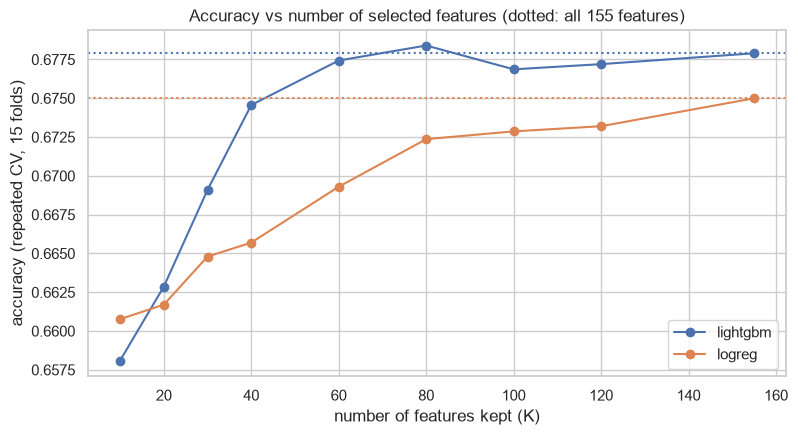

In [4]:
res = pd.DataFrame(results)
fig, ax = plt.subplots(figsize=(9, 4.5))
for m in MODELS:
    d = res[(res["model"] == m) & res["config"].str.startswith(("top", "all v1"))].sort_values("n_features")
    ax.plot(d["n_features"], d["mean"], "o-", label=m)
    ax.axhline(d.loc[d["config"] == "all v1", "mean"].iloc[0], ls=":", c=ax.lines[-1].get_color())
ax.set_xlabel("number of features kept (K)")
ax.set_ylabel("accuracy (repeated CV, 15 folds)")
ax.set_title("Accuracy vs number of selected features (dotted: all 155 features)")
ax.legend()
plt.show()

## 2. Removing redundant features (correlation groups, inside the folds)

`CorrelationFilter` groups the features whose |Spearman r| is above the threshold with complete linkage (every pair
in a group is above it) and keeps the medoid of each group. It never looks at the target.

In [5]:
THRESHOLDS = [0.95, 0.9, 0.8]
t0 = time.time()
for thr in THRESHOLDS:
    n_kept = int(CorrelationFilter(thr).fit(X).support_.sum())     # on the whole train, only to report the size
    for m in MODELS:
        r = compare(m, f"corr filter {thr}", with_selection(CorrelationFilter(thr), MODELS[m]), n_kept)
        print(f"{m:8s} |r| >= {thr}: ~{n_kept} features, {r['mean']:.4f} (gain {r['gain (points)']:+.2f})")
print(f"done in {time.time() - t0:.0f}s")

lightgbm |r| >= 0.95: ~152 features, 0.6765 (gain -0.14)
logreg   |r| >= 0.95: ~152 features, 0.6752 (gain +0.02)
lightgbm |r| >= 0.9: ~148 features, 0.6779 (gain -0.00)
logreg   |r| >= 0.9: ~148 features, 0.6751 (gain +0.01)
lightgbm |r| >= 0.8: ~137 features, 0.6772 (gain -0.07)
logreg   |r| >= 0.8: ~137 features, 0.6749 (gain -0.01)
done in 42s


In [6]:
# Which features are grouped together at |r| >= 0.9 (fitted on the whole train, descriptive only)
cf = CorrelationFilter(0.9).fit(X)
redundant = {kept: [c for c in members if c != kept] for kept, members in cf.groups_.items() if len(members) > 1}
print(f"groups with more than one feature: {len(redundant)} | features removed: {sum(len(v) for v in redundant.values())}")
pd.Series({k: ", ".join(v) for k, v in sorted(redundant.items(), key=lambda kv: -len(kv[1]))}, name="removed (kept feature on the left)").to_frame()

groups with more than one feature: 6 | features removed: 7


,removed (kept feature on the left)
p1_min_level,"p1_n_underlevel, p2_lead_level"
trend_hp_diff_min,trend_hp_diff_mean
p2_ko,p2_first_ko_turn
p1_hp_total,p1_lost_est
p2_boost_def_t30,p2_boost_spe_t30
p1_boost_def_t30,p1_boost_spe_t30


## 3. Removing whole groups

In [7]:
drops = {"without static": ["static"], "without trend": ["trend"], "without static and trend": ["static", "trend"]}
t0 = time.time()
for name, gs in drops.items():
    cols = [c for c in NUM if group_of.get(c) not in gs]
    for m in MODELS:
        r = compare(m, name, MODELS[m], len(cols), cols)
        print(f"{m:8s} {name:26s}: {len(cols)} features, {r['mean']:.4f} (gain {r['gain (points)']:+.2f})")
print(f"done in {time.time() - t0:.0f}s")

lightgbm without static            : 133 features, 0.6778 (gain -0.01)
logreg   without static            : 133 features, 0.6747 (gain -0.03)
lightgbm without trend             : 143 features, 0.6761 (gain -0.18)
logreg   without trend             : 143 features, 0.6738 (gain -0.12)
lightgbm without static and trend  : 121 features, 0.6743 (gain -0.36)
logreg   without static and trend  : 121 features, 0.6734 (gain -0.16)
done in 26s


## 4. PCA (for completeness)

PCA keeps the directions with the largest variance, not the ones that predict the winner, and every component mixes
all features. It is fitted inside the pipeline (imputation → scaling → PCA → model).

In [8]:
def pca_pipeline(model_name, n):
    final = MODELS[model_name].named_steps["model"]
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("pca", PCA(n_components=n, random_state=SEED)), ("model", final)])

t0 = time.time()
for n in [10, 20, 40, 60, 80]:
    r = compare("logreg", f"pca {n}", pca_pipeline("logreg", n), n)
    print(f"logreg   PCA {n:3d}: {r['mean']:.4f} (gain {r['gain (points)']:+.2f})")
for n in [20, 60]:
    r = compare("lightgbm", f"pca {n}", pca_pipeline("lightgbm", n), n)
    print(f"lightgbm PCA {n:3d}: {r['mean']:.4f} (gain {r['gain (points)']:+.2f})")
print(f"done in {time.time() - t0:.0f}s")

logreg   PCA  10: 0.6476 (gain -2.74)
logreg   PCA  20: 0.6654 (gain -0.96)
logreg   PCA  40: 0.6672 (gain -0.78)
logreg   PCA  60: 0.6709 (gain -0.41)
logreg   PCA  80: 0.6719 (gain -0.31)
lightgbm PCA  20: 0.6613 (gain -1.66)
lightgbm PCA  60: 0.6659 (gain -1.20)
done in 18s


## 5. Summary table and decision

Rule fixed before running: adopt a configuration if it gains ≥ 0.3 points, or if it loses ≤ 0.1 points with at most
60% of the features.

In [9]:
summary = pd.DataFrame(results).drop_duplicates(["model", "config"])
summary["adopt"] = (summary["gain (points)"] >= 0.3) | (
    (summary["gain (points)"] >= -0.1) & (summary["n_features"] <= 0.6 * len(NUM)))
summary.loc[summary["config"] == "all v1", "adopt"] = False
summary = summary.sort_values(["model", "mean"], ascending=[True, False])
summary.to_csv(OUT / "feature_selection.csv", index=False)
summary.round(4)

,model,config,n_features,mean,baseline,gain (points),std of gain,folds improved,adopt
7,lightgbm,top 80,80,0.6784,0.6779,0.0500,0.2470,10,True
0,lightgbm,all v1,155,0.6779,0.6779,0.0000,0.0000,0,False
20,lightgbm,corr filter 0.9,148,0.6779,0.6779,-0.0033,0.4072,6,False
24,lightgbm,without static,133,0.6778,0.6779,-0.0100,0.3475,6,False
6,lightgbm,top 60,60,0.6774,0.6779,-0.0467,0.3423,8,True
9,lightgbm,top 120,120,0.6772,0.6779,-0.0700,0.2743,7,False
22,lightgbm,corr filter 0.8,137,0.6772,0.6779,-0.0700,0.3473,7,False
8,lightgbm,top 100,100,0.6769,0.6779,-0.1033,0.3309,5,False
18,lightgbm,corr filter 0.95,152,0.6765,0.6779,-0.1400,0.2354,4,False
26,lightgbm,without trend,143,0.6761,0.6779,-0.1767,0.4061,6,False


In [10]:
candidates = summary[summary["adopt"] & (summary["model"] == "lightgbm")]
if len(candidates):
    # Among the adopted LightGBM configurations prefer the best mean, then the fewest features
    best = candidates.sort_values(["mean", "n_features"], ascending=[False, True]).iloc[0]
    print(f"best adopted LightGBM configuration: {best['config']} | {best['n_features']} features | "
          f"{best['mean']:.4f} ({best['gain (points)']:+.2f} points)")
else:
    best = None
    print("no LightGBM configuration meets the decision rule: keep all v1 features")

best adopted LightGBM configuration: top 80 | 80 features | 0.6784 (+0.05 points)


### 5.1 Stability of the top-K selection

How often each feature is selected across the 15 training folds, for the best K of section 1 (LightGBM). Features
selected in every fold are the stable core; features selected only sometimes are interchangeable with others.

In [11]:
top_rows = summary[(summary["model"] == "lightgbm") & summary["config"].str.startswith("top")]
best_k = int(top_rows.sort_values("mean", ascending=False).iloc[0]["n_features"])
counts = Counter()
t0 = time.time()
for s in REPEAT_SEEDS:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=s)
    out = cross_validate(with_selection(top_k_selector(best_k), MODELS["lightgbm"]), X, y, cv=cv,
                         return_estimator=True, n_jobs=-1)
    for est in out["estimator"]:
        counts.update(selected_columns(est))
stab = pd.DataFrame({"times selected (of 15)": pd.Series(counts)}).assign(group=lambda d: d.index.map(group_of))
stab = stab.sort_values("times selected (of 15)", ascending=False)
print(f"K = {best_k} | done in {time.time() - t0:.0f}s | selected in all 15 folds: {(stab['times selected (of 15)'] == 15).sum()}")
display(stab.groupby("group")["times selected (of 15)"].agg(["size", "mean"]).rename(columns={"size": "n selected at least once"}).round(1))
stab.head(40)

K = 80 | done in 10s | selected in all 15 folds: 59


,n selected at least once,mean
group,,
action,37,11.4
boost,6,10.0
matchup,7,13.0
state,13,12.3
static,17,12.9
status_effect,12,9.2
trend,11,12.6


,times selected (of 15),group
p1_team_mean_base_hp,15,static
p1_team_mean_base_atk,15,static
p1_team_mean_base_def,15,static
p1_team_mean_base_spa,15,static
p1_team_mean_base_spd,15,static
p1_team_mean_base_spe,15,static
p1_team_mean_bst,15,static
p1_team_min_bst,15,static
p2_lead_base_def,15,static
p2_lead_base_spa,15,static


### 5.2 Stress test of the best configuration

Same perturbation of P2's KO recording as experiment 04 (the selection is refitted in every fold).

In [12]:
rows = {"all v1": stress_test(MODELS["lightgbm"], X, y)}
if best is not None:
    cfg = best["config"]
    if cfg.startswith("top"):
        model = with_selection(top_k_selector(int(cfg.split()[1])), MODELS["lightgbm"])
        rows[cfg] = stress_test(model, X, y)
    elif cfg.startswith("corr filter"):
        rows[cfg] = stress_test(with_selection(CorrelationFilter(float(cfg.split()[-1])), MODELS["lightgbm"]), X, y)
    elif cfg.startswith("without"):
        gs = drops[cfg]
        rows[cfg] = stress_test(MODELS["lightgbm"], X[[c for c in NUM if group_of.get(c) not in gs]], y)
st = pd.DataFrame(rows).T
st["drop (points)"] = (st["clean"] - st["p2_ko_fixed_1"]) * 100
st.round(4)

,clean,p2_ko_fixed_0.5,p2_ko_fixed_1,drop (points)
all v1,0.6798,0.6794,0.6794,0.04
top 80,0.6805,0.6797,0.6789,0.16


## 6. Summary

- **Top-K (section 1).** Down to about 60-80 features accuracy does not change: LightGBM top 80 gives 0.6784 vs
  0.6779 with all 155 (+0.05 points, 10/15 folds), top 60 gives 0.6774. Below 40 features it drops quickly (top 10: -2
  points). The logistic regression always loses (top 80: -0.26), so for it every feature adds a little.
- **Redundancy (section 2).** The features are not very redundant: at |r| >= 0.9 only 7 of 155 are removed (6 groups,
  e.g. `p2_ko` / `p2_first_ko_turn`, `p1_hp_total` / `p1_lost_est`), at 0.8 only 18. Accuracy does not move (within
  ±0.14 points).
- **Whole groups (section 3).** Removing `static` costs nothing (-0.01), removing `trend` costs -0.18, both -0.36:
  `static` carries no signal, as in the EDA, but it does not hurt either.
- **PCA (section 4).** Always worse (-0.3 to -2.7 points): the high-variance directions are not the predictive ones.
- **Stability (5.1).** With K = 80, 59 features are selected in all 15 folds. Several of them are `static` (team mean
  base stats): continuous features get some gain in the trees even without signal, so gain importance is not a
  measure of usefulness.
- **Stress test (5.2).** Top 80 drops 0.16 points vs 0.04 for all features: both negligible.

**Decision.** By the rule fixed in advance, LightGBM top 80 (and top 60) is *adopted*: same accuracy with about half
of the features. The gain (+0.05) is well inside the noise, so it is a simplification, not an improvement. Removing
features does not close the train / validation gap of experiment 05: the gap does not come from redundant or noisy
features. All-feature models remain the reference; a top-K selection step can be used in a submission only inside
the pipeline (refitted on the full train).